Name : Raj Patkar

Roll.no : 23102A0013

Sub : R Programming


# Laboratory Assignment 8: High-Performance Big Data Analytics Using R



### 1. Install required packages
Install only the packages needed for this experiment.

In [1]:
options(repos = c(CRAN = "https://cloud.r-project.org"))

packages <- c("data.table", "ggplot2", "foreach", "doParallel", "purrr", "lubridate")
missing <- packages[!vapply(packages, requireNamespace, logical(1), quietly = TRUE)]

if (length(missing)) {
  install.packages(missing, dependencies = NA)
}

invisible(lapply(packages, library, character.only = TRUE))
cat("R:", R.version.string, "\n")
cat("Packages ready.\n")

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependency ‘iterators’



Attaching package: ‘data.table’


The following object is masked from ‘package:base’:

    %notin%


Loading required package: iterators

Loading required package: parallel


Attaching package: ‘purrr’


The following objects are masked from ‘package:foreach’:

    accumulate, when


The following object is masked from ‘package:data.table’:

    transpose



Attaching package: ‘lubridate’


The following objects are masked from ‘package:data.table’:

    hour, isoweek, isoyear, mday, minute, month, quarter, second, wday,
    week, yday, year


The following objects are masked from ‘package:base’:

    date, intersect, setdiff, union




R: R version 4.6.1 (2026-06-24) 
Packages ready.


### 2. Load the manually uploaded dataset
Upload your ZIP file through Colab's Files panel; this cell extracts and locates `df_all.csv` without downloading the trip dataset.

In [2]:
data_dir <- "/content/nyc_taxi_data"
dir.create(data_dir, showWarnings = FALSE, recursive = TRUE)

csv_file <- file.path(data_dir, "df_all.csv")

if (!file.exists(csv_file)) {
  uploaded_zips <- list.files("/content", pattern = "\\.zip$", full.names = TRUE,
                              recursive = FALSE)
  if (length(uploaded_zips) == 0) {
    stop("Upload your taxi dataset ZIP through Colab's Files panel, then rerun this cell.")
  }

  zip_to_use <- uploaded_zips[1]
  unzip(zip_to_use, exdir = data_dir)
}

if (!file.exists(csv_file)) {
  csv_candidates <- list.files("/content", pattern = "^df_all\\.csv$",
                               full.names = TRUE, recursive = TRUE)
  if (length(csv_candidates) == 0) {
    stop("Could not find df_all.csv inside the uploaded ZIP or /content.")
  }
  file.copy(csv_candidates[1], csv_file, overwrite = TRUE)
}

cat("Using trip data:", csv_file, "\\n")
cat("CSV size:", round(file.info(csv_file)$size / 1024^2, 1), "MB\\n")

zone_file <- file.path(data_dir, "taxi_zone_lookup.csv")
if (!file.exists(zone_file)) {
  zone_url <- "https://d37ci6vzurychx.cloudfront.net/misc/taxi_zone_lookup.csv"
  download.file(zone_url, zone_file, mode = "wb", method = "libcurl", quiet = FALSE)
}
cat("Taxi-zone lookup ready.\\n")

Using trip data: /content/nyc_taxi_data/df_all.csv \nCSV size: 263.4 MB\nTaxi-zone lookup ready.\n

trips_raw <- data.table::fread(csv_file, showProgress = TRUE)
zones <- data.table::fread(zone_file)

cat("Rows:", nrow(trips_raw), "\\nColumns:", ncol(trips_raw), "\\n")
str(trips_raw)
summary(trips_raw[, .(passenger_count, trip_distance, fare_amount,
                      tip_amount, tolls_amount, total_amount)])

In [4]:
trips_raw <- data.table::fread(csv_file, showProgress = TRUE)
zones <- data.table::fread(zone_file)

cat("Rows:", nrow(trips_raw), "\nColumns:", ncol(trips_raw), "\n")
str(trips_raw)
summary(trips_raw[, .(passenger_count, trip_distance, fare_amount,
                      tip_amount, tolls_amount, total_amount)])

Rows: 2463931 
Columns: 20 
Classes ‘data.table’ and 'data.frame':	2463931 obs. of  20 variables:
 $ V1                   : int  0 1 2 3 4 5 6 7 8 9 ...
 $ VendorID             : int  1 1 2 2 2 1 2 2 2 2 ...
 $ tpep_pickup_datetime : POSIXct, format: "2022-01-01 00:35:40" "2022-01-01 00:33:43" ...
 $ tpep_dropoff_datetime: POSIXct, format: "2022-01-01 00:53:29" "2022-01-01 00:42:07" ...
 $ passenger_count      : num  2 1 1 1 1 1 1 1 1 1 ...
 $ trip_distance        : num  3.8 2.1 0.97 1.09 4.3 10.3 5.07 2.02 2.71 0.78 ...
 $ RatecodeID           : num  1 1 1 1 1 1 1 1 1 1 ...
 $ store_and_fwd_flag   : chr  "N" "N" "N" "N" ...
 $ PULocationID         : int  142 236 166 114 68 138 233 238 166 236 ...
 $ DOLocationID         : int  236 42 166 68 163 161 87 152 236 141 ...
 $ payment_type         : int  1 1 1 2 1 1 1 2 1 2 ...
 $ fare_amount          : num  14.5 8 7.5 8 23.5 33 17 9 12 5 ...
 $ extra                : num  3 0.5 0.5 0.5 0.5 3 0.5 0.5 0.5 0.5 ...
 $ mta_tax              : num

 passenger_count trip_distance        fare_amount          tip_amount      
 Min.   :0.000   Min.   :0.000e+00   Min.   :  -480.00   Min.   :-125.220  
 1st Qu.:1.000   1st Qu.:1.040e+00   1st Qu.:     6.50   1st Qu.:   0.720  
 Median :1.000   Median :1.740e+00   Median :     9.00   Median :   2.000  
 Mean   :1.389   Mean   :5.373e+00   Mean   :    12.95   Mean   :   2.386  
 3rd Qu.:1.000   3rd Qu.:3.130e+00   3rd Qu.:    14.00   3rd Qu.:   3.000  
 Max.   :9.000   Max.   :3.062e+05   Max.   :401092.32   Max.   : 888.880  
 NAs    :71503                                                             
  tolls_amount      total_amount      
 Min.   :-31.400   Min.   :  -480.30  
 1st Qu.:  0.000   1st Qu.:    11.30  
 Median :  0.000   Median :    14.69  
 Mean   :  0.375   Mean   :    19.17  
 3rd Qu.:  0.000   3rd Qu.:    20.02  
 Max.   :193.300   Max.   :401095.62  
                                      

### 4. Clean and prepare the data
Filter invalid records, remove duplicates, and extract time attributes.

In [5]:
required <- c("tpep_pickup_datetime", "tpep_dropoff_datetime",
              "PULocationID", "DOLocationID", "passenger_count",
              "trip_distance", "fare_amount", "tip_amount",
              "tolls_amount", "total_amount", "payment_type")
missing_cols <- setdiff(required, names(trips_raw))
if (length(missing_cols)) stop(paste("Missing columns:", paste(missing_cols, collapse = ", ")))

trips <- trips_raw[, ..required]
raw_rows <- nrow(trips)

trips[, tpep_pickup_datetime := as.POSIXct(tpep_pickup_datetime, format = "%Y-%m-%d %H:%M:%S", tz = "UTC")]
trips[, tpep_dropoff_datetime := as.POSIXct(tpep_dropoff_datetime, format = "%Y-%m-%d %H:%M:%S", tz = "UTC")]

invalid <- is.na(trips$tpep_pickup_datetime) |
  is.na(trips$tpep_dropoff_datetime) |
  trips$tpep_dropoff_datetime < trips$tpep_pickup_datetime |
  is.na(trips$trip_distance) | trips$trip_distance <= 0 | trips$trip_distance > 100 |
  is.na(trips$fare_amount) | trips$fare_amount <= 0 | trips$fare_amount > 500 |
  is.na(trips$total_amount) | trips$total_amount <= 0 | trips$total_amount > 1000

invalid_count <- sum(invalid)
trips <- unique(trips[!invalid])

trips[, pickup_date := as.Date(tpep_pickup_datetime)]
trips[, pickup_hour := lubridate::hour(tpep_pickup_datetime)]
trips[, pickup_day := lubridate::day(tpep_pickup_datetime)]
trips[, pickup_weekday := factor(weekdays(tpep_pickup_datetime),
  levels = c("Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"))]
trips[, pickup_month := format(tpep_pickup_datetime, "%Y-%m")]

cat("Original rows:", raw_rows, "\nInvalid rows:", invalid_count,
    "\nClean rows:", nrow(trips), "\n")
cat("Working table size:", format(object.size(trips), units = "auto"), "\n")
summary(trips[, .(trip_distance, fare_amount, tip_amount, total_amount)])

Original rows: 2463931 
Invalid rows: 42571 
Clean rows: 2421360 
Working table size: 240.2 Mb 


 trip_distance     fare_amount       tip_amount       total_amount   
 Min.   : 0.010   Min.   :  0.01   Min.   : -3.600   Min.   :  0.31  
 1st Qu.: 1.080   1st Qu.:  6.50   1st Qu.:  1.000   1st Qu.: 11.33  
 Median : 1.770   Median :  9.00   Median :  2.000   Median : 14.72  
 Mean   : 3.155   Mean   : 12.76   Mean   :  2.398   Mean   : 19.05  
 3rd Qu.: 3.170   3rd Qu.: 13.50   3rd Qu.:  3.000   3rd Qu.: 19.98  
 Max.   :99.460   Max.   :499.00   Max.   :888.880   Max.   :899.68  

### 5. Join taxi-zone information
Add pickup and drop-off borough and zone names using `data.table` joins.

In [6]:
pickup_zones <- zones[, .(PULocationID = LocationID,
                             pickup_borough = Borough, pickup_zone = Zone)]
dropoff_zones <- zones[, .(DOLocationID = LocationID,
                           dropoff_borough = Borough, dropoff_zone = Zone)]

trips <- merge(trips, pickup_zones, by = "PULocationID", all.x = TRUE, sort = FALSE)
trips <- merge(trips, dropoff_zones, by = "DOLocationID", all.x = TRUE, sort = FALSE)

print(trips[1:min(5, .N), .(tpep_pickup_datetime, pickup_zone, pickup_borough,
                            dropoff_zone, dropoff_borough, trip_distance, fare_amount)])

   tpep_pickup_datetime             pickup_zone pickup_borough
                 <POSc>                  <char>         <char>
1:  2022-01-01 00:35:40     Lincoln Square East      Manhattan
2:  2022-01-01 00:33:43   Upper East Side North      Manhattan
3:  2022-01-01 00:53:21     Morningside Heights      Manhattan
4:  2022-01-01 00:25:21 Greenwich Village South      Manhattan
5:  2022-01-01 00:36:48            East Chelsea      Manhattan
            dropoff_zone dropoff_borough trip_distance fare_amount
                  <char>          <char>         <num>       <num>
1: Upper East Side North       Manhattan          3.80        14.5
2:  Central Harlem North       Manhattan          2.10         8.0
3:   Morningside Heights       Manhattan          0.97         7.5
4:          East Chelsea       Manhattan          1.09         8.0
5:         Midtown North       Manhattan          4.30        23.5


### 6. Analyze demand and revenue
Calculate trips, average fares, and total revenue by hour, weekday, and month.

In [7]:
hourly_demand <- trips[, .(trips = .N, average_fare = mean(fare_amount),
                              total_revenue = sum(total_amount)), by = pickup_hour][order(pickup_hour)]

weekday_demand <- trips[, .(trips = .N, average_fare = mean(fare_amount),
                            total_revenue = sum(total_amount)), by = pickup_weekday][order(pickup_weekday)]

monthly_demand <- trips[, .(trips = .N, average_fare = mean(fare_amount),
                            total_revenue = sum(total_amount)), by = pickup_month]

print(hourly_demand)
print(weekday_demand)
print(monthly_demand)

    pickup_hour  trips average_fare total_revenue
          <int>  <int>        <num>         <num>
 1:           0  58707     14.23395     1223842.2
 2:           1  41254     13.35283      814267.3
 3:           2  28304     12.72597      536895.9
 4:           3  18584     13.47493      366213.9
 5:           4  12203     15.69948      271586.5
 6:           5  13856     18.54867      354864.8
 7:           6  35367     15.51234      770012.9
 8:           7  72872     13.01532     1373243.8
 9:           8  99908     12.45339     1823531.3
10:           9 107599     12.08237     1917862.7
11:          10 117678     12.10776     2098071.4
12:          11 127326     11.81025     2227460.0
13:          12 139754     11.91358     2465239.9
14:          13 145346     12.46511     2662489.3
15:          14 161148     12.99363     3060214.6
16:          15 171556     13.05035     3278099.3
17:          16 165759     12.96949     3280796.7
18:          17 174044     12.58770     3378367.8


### 7. Find popular and high-revenue routes
Rank pickup and drop-off zone pairs by trip count and total revenue.

In [8]:
route_summary <- trips[!is.na(pickup_zone) & !is.na(dropoff_zone),
  .(trips = .N, total_revenue = sum(total_amount), average_fare = mean(fare_amount)),
  by = .(pickup_borough, pickup_zone, dropoff_borough, dropoff_zone)]

top_routes_by_count <- head(route_summary[order(-trips)], 10)
top_routes_by_revenue <- head(route_summary[order(-total_revenue)], 10)

print(top_routes_by_count)
print(top_routes_by_revenue)

    pickup_borough           pickup_zone dropoff_borough          dropoff_zone
            <char>                <char>          <char>                <char>
 1:      Manhattan Upper East Side South       Manhattan Upper East Side North
 2:      Manhattan Upper East Side North       Manhattan Upper East Side South
 3:      Manhattan Upper East Side North       Manhattan Upper East Side North
 4:      Manhattan Upper East Side South       Manhattan Upper East Side South
 5:        Unknown                   N/A         Unknown                   N/A
 6:      Manhattan       Lenox Hill West       Manhattan Upper East Side North
 7:      Manhattan Upper West Side South       Manhattan Upper West Side North
 8:      Manhattan Upper West Side South       Manhattan   Lincoln Square East
 9:      Manhattan   Lincoln Square East       Manhattan Upper West Side South
10:      Manhattan        Yorkville West       Manhattan       Lenox Hill West
    trips total_revenue average_fare
    <int>      

### 8. Analyze distance and payment preferences
Summarize average fares by trip-distance band and payment type by borough.

In [9]:
distance_fare <- trips[trip_distance <= 30,
  .(trips = .N, average_fare = mean(fare_amount), median_fare = median(fare_amount)),
  by = .(distance_band = cut(trip_distance, c(0, 1, 3, 5, 10, 20, 30), include.lowest = TRUE))]

payment_summary <- trips[!is.na(payment_type),
  .(trips = .N, total_revenue = sum(total_amount)),
  by = .(pickup_borough, payment_type)][order(pickup_borough, -trips)]

print(distance_fare)
print(payment_summary)

   distance_band   trips average_fare median_fare
          <fctr>   <int>        <num>       <num>
1:         (3,5]  293635    15.461465        15.0
2:         (1,3] 1223233     9.127140         8.5
3:         [0,1]  555119     5.558215         5.0
4:       (10,20]  137883    44.765189        47.0
5:        (5,10]  190622    24.108911        23.5
6:       (20,30]   18989    58.925861        52.0
    pickup_borough payment_type   trips total_revenue
            <char>        <int>   <int>         <num>
 1:          Bronx            1    1684      59273.77
 2:          Bronx            2     689      10711.16
 3:          Bronx            0     479      16249.09
 4:          Bronx            3      14        199.55
 5:          Bronx            4       8        178.45
 6:       Brooklyn            1    6614     181232.84
 7:       Brooklyn            0    2912      92553.39
 8:       Brooklyn            2    2254      37476.51
 9:       Brooklyn            3      64        851.35
10:   

### 9. Functional programming
Use `apply()`, `lapply()`, and `purrr::map()` for summaries and daily analysis.

In [10]:
numeric_matrix <- as.matrix(trips[, .(trip_distance, fare_amount, tip_amount, total_amount)])
print(apply(numeric_matrix, 2, mean, na.rm = TRUE))

daily_parts <- split(trips[, .(fare_amount, total_amount)], trips$pickup_date)
daily_lapply <- lapply(daily_parts, function(d) {
  c(trips = nrow(d), average_fare = mean(d$fare_amount), revenue = sum(d$total_amount))
})
print(head(daily_lapply, 5))

daily_map <- purrr::map_dfr(names(daily_parts), function(day) {
  d <- daily_parts[[day]]
  data.frame(date = as.Date(day), trips = nrow(d),
             average_fare = mean(d$fare_amount), revenue = sum(d$total_amount))
})
print(head(daily_map, 10))

trip_distance   fare_amount    tip_amount  total_amount 
     3.155108     12.760060      2.398029     19.047776 
$`2008-12-31`
       trips average_fare      revenue 
     6.00000     17.66667    146.82000 

$`2009-01-01`
       trips average_fare      revenue 
     6.00000     17.08333    140.55000 

$`2021-12-31`
       trips average_fare      revenue 
    23.00000     12.69565    431.20000 

$`2022-01-01`
       trips average_fare      revenue 
6.207300e+04 1.454195e+01 1.301536e+06 

$`2022-01-02`
       trips average_fare      revenue 
  57185.0000      15.9228 1300665.5600 

         date trips average_fare    revenue
1  2008-12-31     6     17.66667     146.82
2  2009-01-01     6     17.08333     140.55
3  2021-12-31    23     12.69565     431.20
4  2022-01-01 62073     14.54195 1301536.40
5  2022-01-02 57185     15.92280 1300665.56
6  2022-01-03 70803     14.28654 1482391.40
7  2022-01-04 73199     13.44065 1451960.17
8  2022-01-05 73200     13.01443 1414717.19
9  2022-01-06 7

### 10. Benchmark alternative implementations
Compare Base R, `lapply()`, `purrr::map()`, vectorized grouping, and `data.table` on the same sample.

In [12]:
set.seed(42)
benchmark_data <- trips[sample.int(nrow(trips), min(100000L, nrow(trips))),
                         .(pickup_hour, fare_amount)]
benchmark_data <- benchmark_data[!is.na(pickup_hour) & is.finite(fare_amount)]
benchmark_df <- as.data.frame(benchmark_data)

hourly_base <- function(d) aggregate(fare_amount ~ pickup_hour, d, mean)
hourly_lapply <- function(d) {
  x <- split(d$fare_amount, d$pickup_hour)
  data.frame(pickup_hour = as.integer(names(x)), fare_amount = vapply(x, mean, numeric(1)))
}
hourly_map <- function(d) {
  x <- split(d$fare_amount, d$pickup_hour)
  data.frame(pickup_hour = as.integer(names(x)), fare_amount = purrr::map_dbl(x, mean))
}
hourly_vectorized <- function(d) {
  sums <- rowsum(d$fare_amount, d$pickup_hour, reorder = TRUE)
  counts <- rowsum(rep.int(1L, nrow(d)), d$pickup_hour, reorder = TRUE)
  data.frame(pickup_hour = as.integer(rownames(sums)),
             fare_amount = as.numeric(sums[, 1] / counts[, 1]))
}
hourly_datatable <- function(d) data.table::as.data.table(d)[,
  .(fare_amount = mean(fare_amount)), by = pickup_hour][order(pickup_hour)]

normalize <- function(x) {
  df <- as.data.frame(x)
  # Force types and order to ensure identical comparison structure
  res <- data.frame(
    pickup_hour = as.integer(df$pickup_hour),
    fare_amount = as.numeric(df$fare_amount)
  )
  res[order(res$pickup_hour), ]
}

reference <- normalize(hourly_base(benchmark_df))
for (fn in list(hourly_lapply, hourly_map, hourly_vectorized, hourly_datatable)) {
  stopifnot(isTRUE(all.equal(reference, normalize(fn(benchmark_df)), tolerance = 1e-8)))
}

timings <- lapply(list(Base_R = hourly_base, lapply = hourly_lapply,
                       purrr_map = hourly_map, Vectorized = hourly_vectorized,
                       data_table = hourly_datatable), function(fn) {
  unname(replicate(5, system.time(fn(benchmark_df))[["elapsed"]]))
})
benchmark_summary <- data.table(
  implementation = names(timings),
  median_seconds = vapply(timings, median, numeric(1)),
  min_seconds = vapply(timings, min, numeric(1)),
  max_seconds = vapply(timings, max, numeric(1))
)[order(median_seconds)]
print(benchmark_summary)

   implementation median_seconds min_seconds max_seconds
           <char>          <num>       <num>       <num>
1:         lapply          0.005       0.004       0.010
2:      purrr_map          0.005       0.005       0.010
3:     Vectorized          0.006       0.006       0.014
4:     data_table          0.009       0.008       0.015
5:         Base_R          0.064       0.060       0.072


### 11. Compare sequential and parallel processing
Aggregate a fixed sample sequentially and with `foreach` and `doParallel`, then calculate speedup.

In [13]:
set.seed(123)
parallel_data <- trips[sample.int(nrow(trips), min(300000L, nrow(trips))),
                       .(pickup_hour, total_amount)]
parallel_data[, chunk_id := ((.I - 1L) %% 8L) + 1L]
parts <- split(parallel_data, parallel_data$chunk_id)

seq_time <- system.time({
  seq_partial <- rbindlist(lapply(parts, function(d)
    d[, .(trip_count = .N, revenue = sum(total_amount)), by = pickup_hour]))
  seq_result <- seq_partial[, .(trip_count = sum(trip_count), revenue = sum(revenue)),
                            by = pickup_hour][order(pickup_hour)]
})[["elapsed"]]

cores <- parallel::detectCores(logical = TRUE)
workers <- max(1L, min(2L, cores - 1L))
cluster <- parallel::makeCluster(workers)
doParallel::registerDoParallel(cluster)

par_time <- system.time({
  par_partial <- foreach(part = parts, .combine = rbind, .packages = "data.table") %dopar% {
    as.data.table(part)[, .(trip_count = .N, revenue = sum(total_amount)),
                        by = pickup_hour]
  }
  setDT(par_partial)
  par_result <- par_partial[, .(trip_count = sum(trip_count), revenue = sum(revenue)),
                            by = pickup_hour][order(pickup_hour)]
})[["elapsed"]]

parallel::stopCluster(cluster)
foreach::registerDoSEQ()
stopifnot(isTRUE(all.equal(seq_result, par_result, tolerance = 1e-8)))

parallel_summary <- data.table(method = c("Sequential", "Parallel"),
                               elapsed_seconds = c(seq_time, par_time),
                               workers = c(1L, workers))
print(parallel_summary)
cat("Speedup:", round(seq_time / par_time, 3), "x\n")

       method elapsed_seconds workers
       <char>           <num>   <int>
1: Sequential           0.022       1
2:   Parallel           0.346       1
Speedup: 0.064 x


### 12. Visualize findings
Create labeled plots for hourly demand, weekday demand, fare by distance, frequent routes, payment type, and fare versus distance.

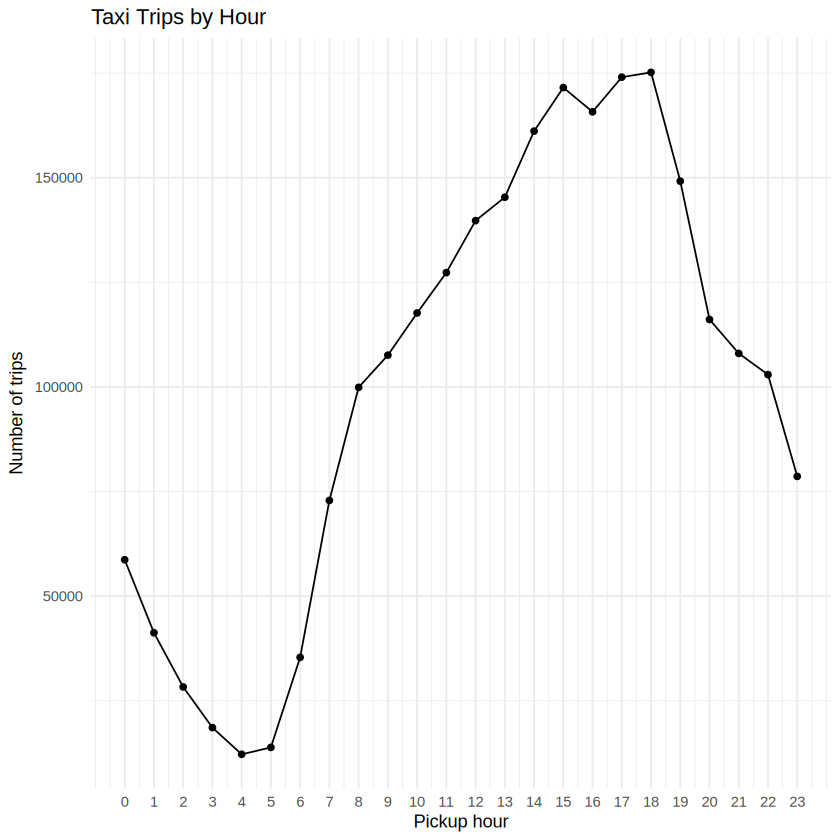

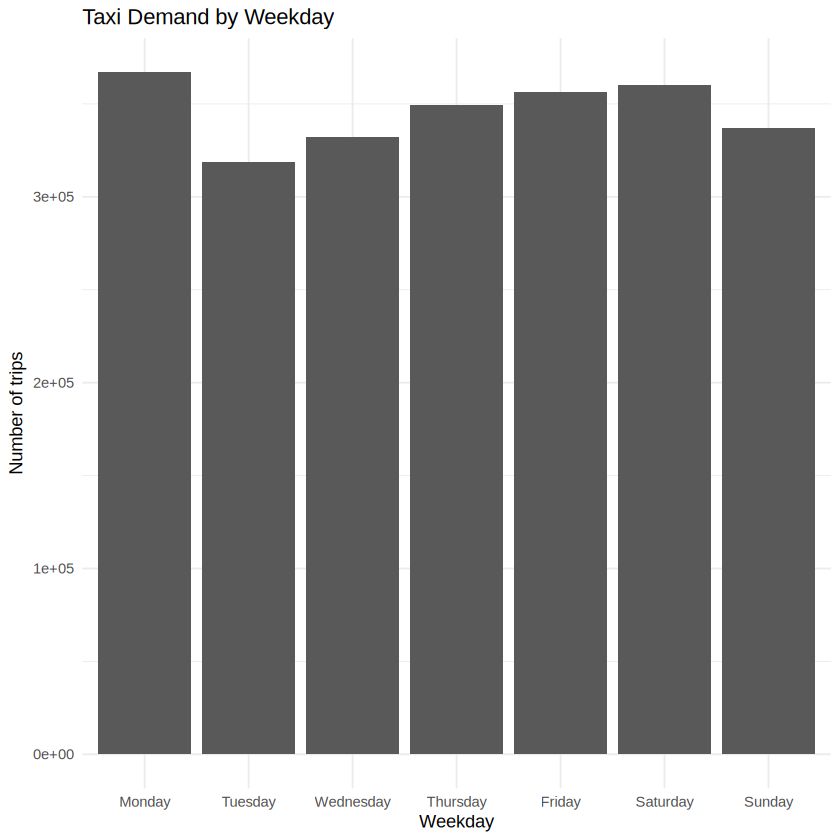

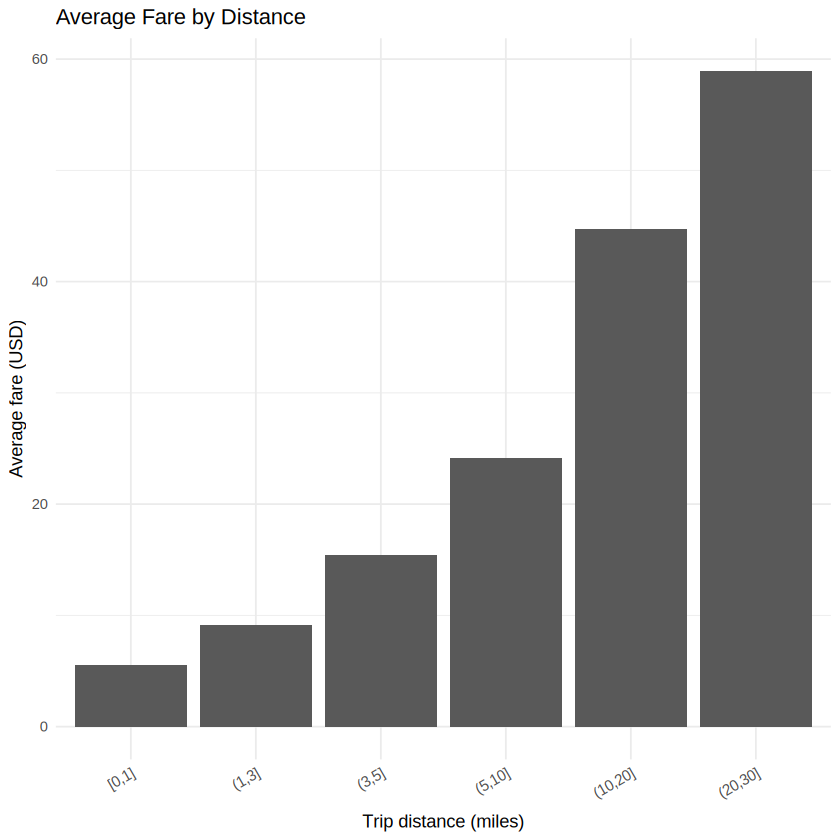

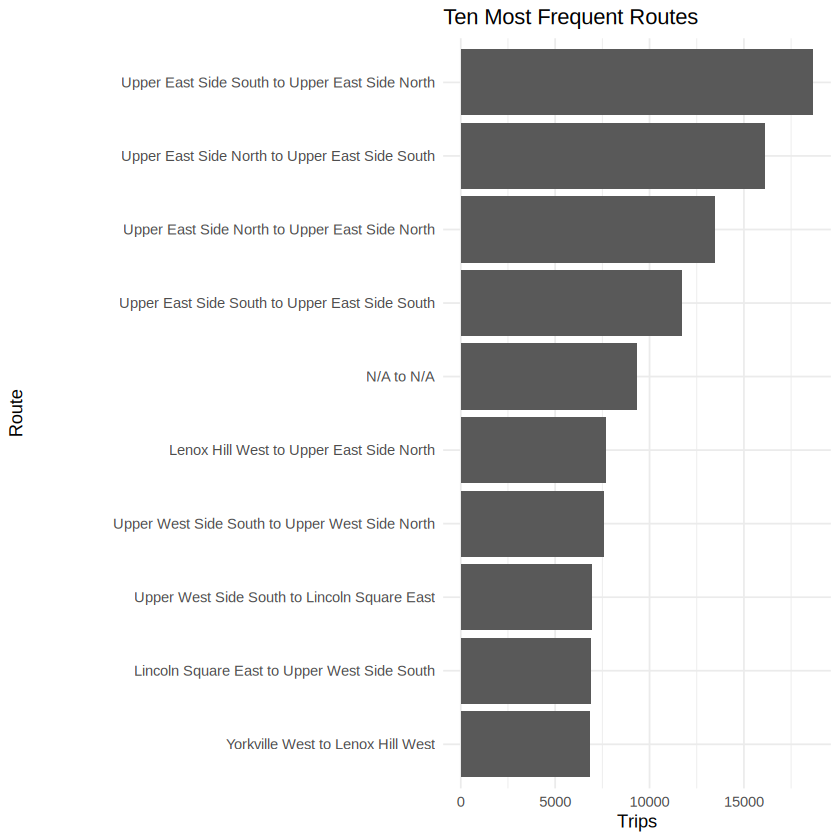

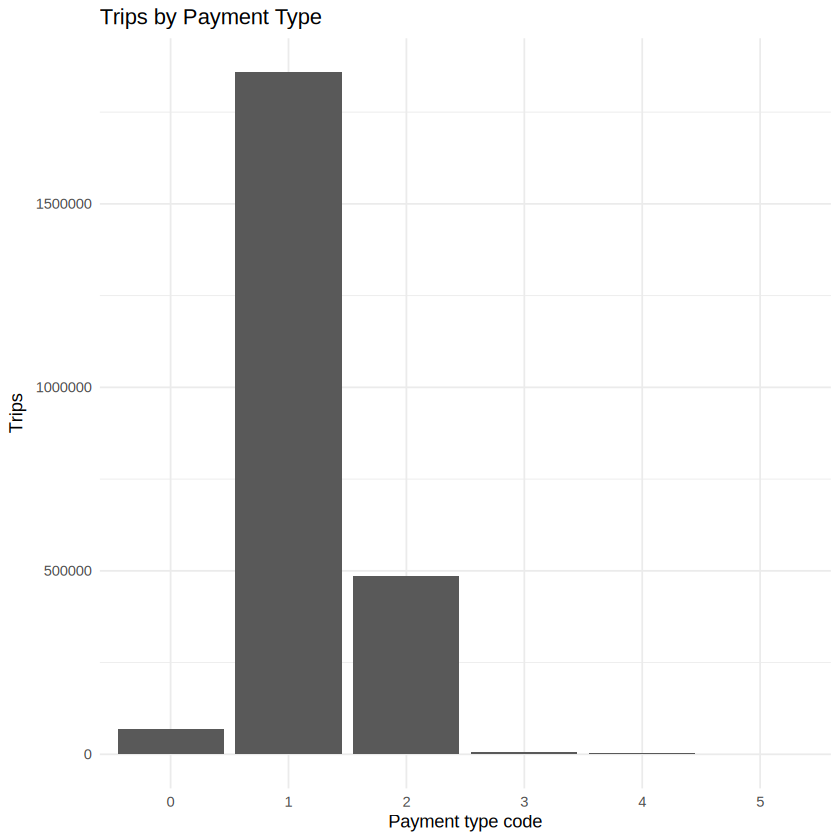

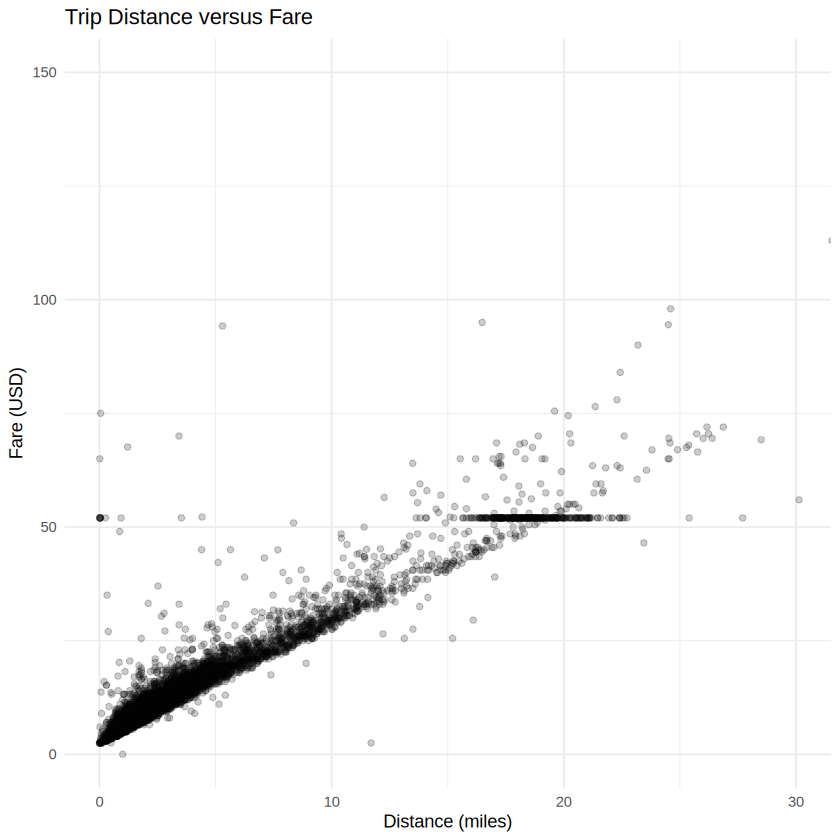

In [14]:
library(ggplot2)

print(ggplot(hourly_demand, aes(pickup_hour, trips)) +
  geom_line() + geom_point() + scale_x_continuous(breaks = 0:23) +
  labs(title = "Taxi Trips by Hour", x = "Pickup hour", y = "Number of trips") + theme_minimal())

print(ggplot(weekday_demand, aes(pickup_weekday, trips)) +
  geom_col() + labs(title = "Taxi Demand by Weekday", x = "Weekday", y = "Number of trips") +
  theme_minimal())

print(ggplot(distance_fare, aes(distance_band, average_fare)) +
  geom_col() + labs(title = "Average Fare by Distance", x = "Trip distance (miles)",
                    y = "Average fare (USD)") + theme_minimal() +
  theme(axis.text.x = element_text(angle = 30, hjust = 1)))

route_plot <- copy(top_routes_by_count)
route_plot[, route := paste(pickup_zone, "to", dropoff_zone)]
print(ggplot(route_plot, aes(reorder(route, trips), trips)) + geom_col() + coord_flip() +
  labs(title = "Ten Most Frequent Routes", x = "Route", y = "Trips") + theme_minimal())

payment_plot <- trips[!is.na(payment_type), .(trips = .N), by = payment_type]
print(ggplot(payment_plot, aes(factor(payment_type), trips)) + geom_col() +
  labs(title = "Trips by Payment Type", x = "Payment type code", y = "Trips") + theme_minimal())

set.seed(7)
scatter <- trips[sample.int(nrow(trips), min(10000L, nrow(trips))),
                 .(trip_distance, fare_amount)]
print(ggplot(scatter, aes(trip_distance, fare_amount)) + geom_point(alpha = 0.2) +
  coord_cartesian(xlim = c(0, 30), ylim = c(0, 150)) +
  labs(title = "Trip Distance versus Fare", x = "Distance (miles)", y = "Fare (USD)") +
  theme_minimal())

cat("Peak demand hour:", hourly_demand[which.max(hourly_demand$trips), pickup_hour], "\\n")
cat("Peak weekday:", as.character(weekday_demand[which.max(weekday_demand$trips), pickup_weekday]), "\\n")
cat("Most frequent route:", top_routes_by_count[1, pickup_zone], "to",
    top_routes_by_count[1, dropoff_zone], "\\n")
cat("Fastest measured implementation:", benchmark_summary[1, implementation], "\\n")
cat("Sequential seconds:", seq_time, "Parallel seconds:", par_time,
    "Speedup:", round(seq_time / par_time, 3), "x\\n")

In [15]:
cat("Peak demand hour:", hourly_demand[which.max(trips), pickup_hour], "\n")
cat("Peak weekday:", as.character(weekday_demand[which.max(trips), pickup_weekday]), "\n")
cat("Most frequent route:", top_routes_by_count[1, pickup_zone], "to",
    top_routes_by_count[1, dropoff_zone], "\n")
cat("Fastest measured implementation:", benchmark_summary[1, implementation], "\n")
cat("Sequential seconds:", seq_time, "Parallel seconds:", par_time,
    "Speedup:", round(seq_time / par_time, 3), "x\n")

Peak demand hour: 18 
Peak weekday: Monday 
Most frequent route: Upper East Side South to Upper East Side North 
Fastest measured implementation: lapply 
Sequential seconds: 0.022 Parallel seconds: 0.346 Speedup: 0.064 x


### 14. Critical analysis

- `data.table` is suitable for large grouped aggregations and joins.
- Vectorized operations can reduce interpreted loop overhead.
- Functional programming is useful for repeated transformations, though splitting data can add overhead.
- Parallel processing helps only when its gains exceed worker startup and data-transfer costs.
- Temporary objects and parallel workers can increase memory usage.
- Prefer `data.table` for the main workflow and parallel execution only when measurements show a benefit.

### Conclusion

The experiment analyzes NYC Yellow Taxi records and compares alternative R implementations using actual execution times. The final recommendation should be based on measured speed, memory requirements, readability, and scalability.

**Data source:** [NYC TLC Trip Record Data](https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page).